In [1]:
import Orange
from orangecontrib.spectroscopy import data

In [2]:
import numpy as np
import pandas as pd

In [3]:
from orangecontrib.spectroscopy.data import getx

In [4]:
def read_spectra(self):
        channels = self.get_channels()

        for c, label in channels.items():
            if label.decode("utf-8") == self.sheet:
                self.data_signal = c
                break
        else:
            self.data_signal = list(channels.keys())[0]

        import h5py
        hdf5_file = h5py.File(self.filename,'r')
        keys = list(hdf5_file.keys())

        hyperspectra = False
        intensities = []
        wavenumbers = []
        x_locs = []
        y_locs = []

        # load measurements
        for meas_name in filter(lambda s: s.startswith('Measurement'), keys):
            hdf5_meas = hdf5_file[meas_name]

            meas_keys = list(hdf5_meas.keys())
            meas_attrs = hdf5_meas.attrs

            # check if this measurement contains the selected data channel
            selected_signal = False
            for chan_name in filter(lambda s: s.startswith('Channel'), meas_keys):
                hdf5_chan = hdf5_meas[chan_name]
                if hdf5_chan.attrs.keys().__contains__('DataSignal') and hdf5_chan.attrs['DataSignal'] == self.data_signal:
                    selected_signal = True
                    break
            if not selected_signal:
                continue

            # build range arrays
            spec_vals = []
            try:
                if meas_attrs.keys().__contains__('RangeWavenumberStart'):
                    wn_start = meas_attrs['RangeWavenumberStart'][0]
                    wn_end = meas_attrs['RangeWavenumberEnd'][0]
                    wn_points = meas_attrs['RangeWavenumberPoints'][0]
                    spec_vals = np.linspace(wn_start, wn_end, wn_points)
            except:
                raise IOError("Error reading wavenumber range from " + self.filename)

            pos_vals = []
            try:
                if meas_attrs.keys().__contains__('RangeXStart'):
                    x_start = meas_attrs['RangeXStart'][0]
                    x_points = meas_attrs['RangeXPoints'][0]
                    x_incr = meas_attrs['RangeXIncrement'][0]
                    x_end = x_start + x_incr * (x_points - 1)
                    x_min = min(x_start, x_end)
                    if meas_attrs.keys().__contains__('RangeYStart'):
                        y_start = meas_attrs['RangeYStart'][0]
                        y_points = meas_attrs['RangeYPoints'][0]
                        y_incr = meas_attrs['RangeYIncrement'][0]
                        y_end = y_start + y_incr * (y_points - 1)
                        y_min = min(y_start, y_end)

                        # construct the positions array
                        for iY in range(int(y_points)):
                            y = y_min + iY * abs(y_incr)
                            for iX in range(int(x_points)):
                                x = x_min + iX * abs(x_incr)
                                pos_vals.append([x, y])
                        pos_vals = np.array(pos_vals)
                else:
                    pos_vals = np.array([1])
            except:
                raise IOError("Error reading position data from " + self.filename)

            hyperspectra = pos_vals.shape[0] > 1

            # ignore backgrounds and unchecked data
            if not hyperspectra:
                if meas_attrs.keys().__contains__('IsBackground') and meas_attrs['IsBackground'][0]:
                    continue
                if meas_attrs.keys().__contains__('Checked') and not meas_attrs['Checked'][0]:
                    continue

            if len(wavenumbers) == 0:
                wavenumbers = spec_vals

            if hyperspectra:
                x_len = meas_attrs['RangeXPoints'][0]
                y_len = meas_attrs['RangeYPoints'][0]
                x_locs = pos_vals[:x_len,0]
                y_indices = np.round(np.linspace(0, pos_vals.shape[0] - 1, y_len)).astype(int)
                y_locs = pos_vals[y_indices,1]
            else:
                x_locs.append(meas_attrs['LocationX'][0])
                y_locs.append(meas_attrs['LocationY'][0])

            # load channels
            for chan_name in filter(lambda s: s.startswith('Channel'), meas_keys):
                hdf5_chan = hdf5_meas[chan_name]
                chan_attrs = hdf5_chan.attrs

                signal = chan_attrs['DataSignal']
                if signal != self.data_signal:
                    continue

                data = hdf5_chan['Raw_Data']
                if hyperspectra:
                    rows = meas_attrs['RangeYPoints'][0]
                    cols = meas_attrs['RangeXPoints'][0]
                    intensities = np.reshape(data, (rows,cols,data.shape[1])) # organized rows, columns, wavelengths
                    break
                else:
                    intensities.append(data[0,:])

        #intensities = np.array(intensities)
        #features = np.array(wavenumbers)
        intensities = intensities
        features = np.array(wavenumbers)
        x_locs = np.array(x_locs).flatten()
        y_locs = np.array(y_locs).flatten()
        if hyperspectra:
            return _spectra_from_image(intensities, features, x_locs, y_locs)
        else:
            spectra = intensities

            # locations
            x_loc = y_loc = np.arange(len(spectra))
            metas = np.array([x_locs[x_loc], y_locs[y_loc]]).T

            domain = Orange.data.Domain([], None,
                                        metas=[Orange.data.ContinuousVariable.make("map_x"),
                                               Orange.data.ContinuousVariable.make("map_y")]
                                        )
            data = Orange.data.Table.from_numpy(domain, X=np.zeros((len(spectra), 0)),
                                                metas=np.asarray(metas, dtype=object))
            return features, spectra, data
        
Orange.data.io.FileFormat.read_spectra = read_spectra


In [6]:
from Orange.data.io import FileFormat

#absolute_filename = FileFormat.locate('MNEC_Back.ptir')
absolute_filename = FileFormat.locate('/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/OPTIR/MEC_02_068_OPTIR/MEC_02_068_FHS_AlSI_1_051023_06072023_Run1.ptir')
reader = FileFormat.get_reader(absolute_filename)
#reader.select_sheet(sheet)
#data = reader.read()
read_spectra(reader)

(array([ 948.,  950.,  952., ..., 3000., 3002., 3004.]),
 [array([32.174774 , 33.65764  , 34.959293 , ...,  2.4730182,  2.7020519,
          3.1921275], dtype=float32),
  array([ 0.41353855,  0.49662682, -0.00633508, ...,  1.9475721 ,
          0.9944686 ,  0.69637406], dtype=float32),
  array([-0.6113614 , -0.35425955, -1.0535984 , ...,  0.8065729 ,
          0.9159254 , -4.4161634 ], dtype=float32),
  array([-0.07195922, -0.57875645,  0.08633855, ..., -0.33840647,
          1.4768411 , -3.5364947 ], dtype=float32),
  array([ 2.7573202 ,  0.6863507 , -0.22201994, ...,  0.72756034,
          3.8865488 ,  7.5034833 ], dtype=float32),
  array([-0.15497844, -0.49837142, -0.01045222, ..., -2.134103  ,
         -3.9856968 , -2.4145286 ], dtype=float32),
  array([-1.1455672 , -0.20410137, -0.35216093, ..., -1.1793962 ,
         -0.9607518 , -0.32082385], dtype=float32),
  array([-0.24633192,  0.6377017 ,  0.80692875, ...,  1.8479322 ,
          1.0782905 ,  1.7656566 ], dtype=float32),
  arr

In [137]:
absolute_filename = FileFormat.locate('MNEC_Back.ptir')

In [139]:
FileFormat.open('MNEC_Back.ptir')

<_io.TextIOWrapper name='MNEC_Back.ptir' mode='r' encoding='UTF-8'>

In [141]:
reader = FileFormat

In [144]:
reader.get_reader(absolute_filename)

MissingReaderException: No readers for file "MNEC_Back.ptir"

In [160]:
FileFormat.sheets

TypeError: 'property' object is not callable

In [119]:


reader = FileFormat.get_reader(absolute_filename)
reader.select_sheet(None)
spectra = reader.read_spectra()
_ = plt.plot(np.array([s if s.shape[0] > 1000 else np.zeros(1029) for s in spectra[1]]).T)

MissingReaderException: No readers for file "MNEC_Back.ptir"

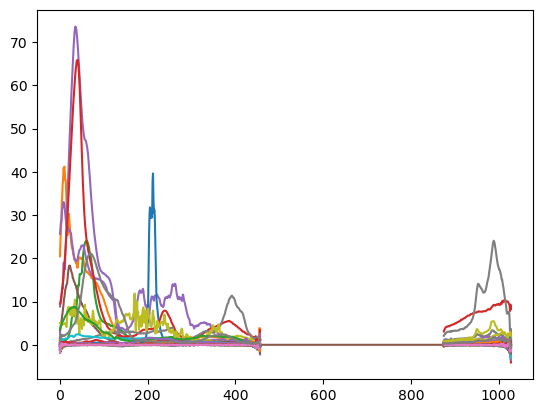

In [86]:
d = Orange.data.Table('MNEC_02_057_03-29-2023--04-12-2023_FHS_Back.ptir')

OSError: File "MNEC_02_057_03-29-2023--04-12-2023_FHS_Back.ptir" was not found.

In [87]:
file = data.PTIRFileReader.open('MNEC_Back.ptir')
file

<_io.TextIOWrapper name='MNEC_Back.ptir' mode='r' encoding='UTF-8'>

In [4]:
d2 = Orange.data.Table('MEC_03_026_S1.ptir')
d2 = (
    d2.
    X_df.T.
    reset_index().
    astype('float32').
    set_index('index'))
d2

,_o10,_o11,_o12,_o13,_o14,_o15,_o16,_o17,_o18,_o19
index,,,,,,,,,,
948.0,2.243156,5.134576,2.456903,7.397571,0.237409,0.189612,0.147993,2.199891,4.290390,-0.240645
950.0,2.706214,5.480681,2.558830,8.146533,0.081963,0.315846,0.010196,2.597506,4.547463,-0.151741
952.0,2.800978,5.833579,2.762177,8.804046,0.252426,0.538099,0.053017,2.908425,5.230546,-0.176159
954.0,2.957413,6.005155,2.745975,9.163743,0.304000,0.597790,0.168481,3.175253,5.542913,-0.214537
956.0,2.728234,6.030700,2.718388,9.318854,0.307781,0.613401,0.184617,3.428245,5.672351,-0.120769
...,...,...,...,...,...,...,...,...,...,...
2996.0,-0.131785,0.079708,0.026055,0.128424,-0.149157,-0.067096,0.132865,0.548638,4.777115,-0.169429
2998.0,-0.092094,0.076792,-0.145219,0.135724,-0.187958,-0.022031,0.085787,0.621686,4.761178,-0.296760
3000.0,-0.090754,0.011282,-0.052689,0.158655,-0.054720,-0.070057,0.167610,0.637287,4.794749,-0.338855


In [5]:
_ = plt.plot(d2)

NameError: name 'plt' is not defined

In [13]:
from Orange.data.io import FileFormat

absolute_filename = FileFormat.locate('MEC_20X_1.75_2.5_PSLs.ptir')
reader = FileFormat.get_reader(absolute_filename)
#reader.select_sheet(sheet)
#data = reader.read()
read_spectra(reader)

AttributeError: 'OPUSReader' object has no attribute 'get_channels'

In [14]:
d2 = Orange.data.Table('MEC_20X_1.75_2.5_PSLs.ptir')
#d2 = (
#    d2.
#    X_df.T.
#    reset_index().
#    astype('float32').
#    set_index('index'))
d2

ValueError: Can't process a non-Opus file

In [157]:
d = Orange.data.Table('MEC_02_059_PET.csv')

In [11]:
d1 = Orange.data.Table('MEC_02_059_PET.csv')
d1 = (
    d1.
    X_df.T.
    reset_index().
    astype('float32').
    set_index('index'))
d1

ValueError: could not convert string to float: 'X value [cm⁻¹] (1)'

In [91]:
plt.plot(d1)

NameError: name 'plt' is not defined

In [92]:
import matplotlib.pyplot as plt

In [93]:
d1

NameError: name 'd1' is not defined

In [94]:
np.array(d[0])

NameError: name 'd' is not defined

In [95]:
plt.plot(d[0]
    )

NameError: name 'd' is not defined

In [96]:
df.loc[np.logical_not(pd.isna(df.iloc[:,4])),:]

NameError: name 'df' is not defined

In [97]:
df_IR = df.iloc[:,:4]
df_IR = df_IR.astype('float32').set_index('X value [cm⁻¹]')
df_IR

NameError: name 'df' is not defined

In [98]:
((df_IR - df_IR.min())  / (df_IR.max() - df_IR.min()))

NameError: name 'df_IR' is not defined

In [99]:
plt.plot(1-((df_IR - df_IR.min())  / (df_IR.max() - df_IR.min())))

plt.plot((df_ - df_.min()) / (df_.max() - df_.min()))

NameError: name 'df_IR' is not defined

In [100]:
df_all = pd.read_csv('/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/spectral_data_all.csv')

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_70905/2348156239.py:1: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  df_all = pd.read_csv('/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/spectral_data_all.csv')


In [101]:
df_ =  df_all.query('file_name == "PET 1. Red Bottle Fragment.CSV" and intensity > 0').loc[:,['wavelength', 'intensity']].set_index('wavelength')




In [102]:
#plt.scatter(
#    np.float32(d.X_df.columns.to_numpy()),
#    d.X,
#    s=1
#    )

plt.scatter(
    df.iloc[:,0],
    df.iloc[:,2],
    s=1
)


NameError: name 'df' is not defined

In [ ]:
df = pd.read_csv('MEC_02_059_PET.csv')

In [103]:
df1 =pd.read_csv('MEC_02_059_PE_redPE_polyamide.csv')

In [104]:
df1

,X value [cm⁻¹],Raman2_polyamide_300um/Raman Intensity [],Raman2_polyamide_300um/Raman Intensity [].1,Raman 6_clear_PE_53um/Raman Intensity [],Raman 6_clear_PE_53um/Raman Intensity [].1,X value [cm⁻¹].1,IR3_red_PE_45um/OPTIR (mV) [mV],IR3_red_PE_45um/OPTIR (mV) [mV].1,IR4_red_PE_45um/OPTIR (mV) [mV],IR4_red_PE_45um/OPTIR (mV) [mV].1,IR5_clear_PE_53um/OPTIR (mV) [mV],IR5_clear_PE_53um/OPTIR (mV) [mV].1
0,326.122151,1304.333374,1304.333374,2515.666748,2515.666748,948.000000,0.429541,0.429541,42.298027,42.298027,0.021076,0.021076
1,329.593769,1323.536865,1323.536865,2510.405518,2510.405518,950.000000,0.442037,0.442037,57.351879,57.351879,0.004419,0.004419
2,333.065387,1355.474976,1355.474976,2499.092529,2499.092529,952.000000,0.362219,0.362219,65.118011,65.118011,0.006857,0.006857
3,336.537004,1363.001343,1363.001343,2530.300293,2530.300293,954.000000,0.358371,0.358371,67.455513,67.455513,-0.005676,-0.005676
4,340.008622,1346.754272,1346.754272,2594.496338,2594.496338,956.000000,0.427593,0.427593,85.908722,85.908722,-0.006365,-0.006365
...,...,...,...,...,...,...,...,...,...,...,...,...
1024,NaN,2996.000000,0.096017,0.096017,-16.977449,-16.977449,0.011514,0.011514,NaN,NaN,NaN,NaN
1025,NaN,2998.000000,-0.064158,-0.064158,12.217678,12.217678,0.005687,0.005687,NaN,NaN,NaN,NaN
1026,NaN,3000.000000,-0.057491,-0.057491,7.916257,7.916257,-0.031016,-0.031016,NaN,NaN,NaN,NaN
1027,NaN,3002.000000,-0.118490,-0.118490,-41.453114,-41.453114,-0.055531,-0.055531,NaN,NaN,NaN,NaN
